# 1.0 Carga, exploración (EDA) y preprocesamiento – Consumidores hipervulnerables

**Proyecto de Aprendizaje Automático – Centro Politécnico Superior Malvinas Argentinas**

**Objetivo del notebook:** cargar el dataset, explorarlo (instancias, columnas, tipos de datos, calidad,
distribuciones, asociaciones) y dejarlo preparado para entrenar modelos: normalización de formato, agrupación
de rubros, selección de variables, codificación de variables categóricas, escalado y partición
entrenamiento/prueba. **En este notebook no se entrena ningún modelo** (el modelado va en un notebook aparte).

La descripción del dataset y su origen están en `docs/01_descripcion_dataset.md`; las decisiones y su
justificación, en `docs/02_decisiones_metodologicas.md`.

**Fuente:** Datos Argentina, Ministerio de Desarrollo Productivo. Programa Consumidores Hipervulnerables.
El enlace y la fecha de descarga están en el `README.md` del repositorio.

> Todo el análisis se refiere únicamente a los **reclamos registrados** en el dataset y a su período. No
> permite afirmar nada sobre las personas que no reclamaron ni sobre cuántas personas de cada grupo
> consumen cada servicio. Las explicaciones posibles de lo que se observa se presentan como **hipótesis**.


In [1]:
# Importaciones: pandas/numpy para manejar datos, matplotlib para los gráficos y scikit-learn solo para
# el preprocesamiento (partición, codificación y escalado). No se importa ningún modelo.
import sys
sys.path.insert(0, "..")  # permite importar el módulo del repositorio desde la carpeta notebooks

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Funciones propias (carga, limpieza, agrupación de rubros, V de Cramér) definidas en
# consumidores_hipervulnerables/dataset.py para que el código quede reutilizable.
from consumidores_hipervulnerables.dataset import (
    INTERIM, PROCESSED, agrupar_rubros, cargar_crudo, cramer_v, normalizar,
)

FIG = Path("../reports/figures")          # carpeta donde se guardan los gráficos
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 150)        # evita que las tablas anchas se corten
pd.set_option("display.max_colwidth", 70)
SEMILLA = 42  # semilla fija: la partición entrenamiento/prueba será siempre la misma


## 1. Carga y estructura del archivo original

In [2]:
# Se lee el CSV tal como viene (latin-1) para conocer su estructura antes de tocar nada.
raw = cargar_crudo()
print("Instancias (filas):", raw.shape[0])
print("Características (columnas):", raw.shape[1])
print("Columnas tal como vienen en el archivo:", list(raw.columns))
raw.head(3)  # primeras filas para ver el contenido real

Instancias (filas): 6457
Características (columnas): 8
Columnas tal como vienen en el archivo: ['rubro', 'motivo', 'vulnerabilidad', 'mes_año_tratamiento', 'edad', 'genero', 'provincia_consumidor', 'provincia_id;;;']


,rubro,motivo,vulnerabilidad,mes_año_tratamiento,edad,genero,provincia_consumidor,provincia_id;;;
0,Servicios de comunicaciones,Cumplimiento parcial o defectuoso de la prestación del servicio,Adulto/a mayor,ene-21,51,Femenino,Buenos Aires,6;;;
1,Servicios de comunicaciones,Facturación excesiva/ facturación cargos no convenidos,Socio-económica,feb-21,64,Masculino,Ciudad Autónoma de Buenos Aires,2;;;
2,Servicios de comunicaciones,Cumplimiento parcial o defectuoso de la prestación del servicio,Adulto/a mayor,feb-21,46,Femenino,Buenos Aires,6;;;


El encabezado de la última columna viene como `provincia_id;;;` y cada valor de esa columna termina con `;;;`
(restos de un separador). El archivo está codificado en latin-1. El archivo original **no se modifica**: las
correcciones se aplican en memoria con `normalizar()`.

**Qué representa cada fila:** un **reclamo de un consumidor** registrado por el programa (con el rubro del
bien o servicio reclamado, el motivo, el perfil de la persona y el mes de tratamiento). No hay identificador de
reclamo ni de persona.

**Tipo de problema:** clasificación **multiclase** (multinomial), no binaria: la variable a predecir tiene más
de dos valores posibles.

## 2. Normalización de formato (sin eliminar filas)

In [3]:
# normalizar(): renombra columnas, quita ';;;' de provincia_id, recorta espacios sobrantes en los textos,
# unifica 'Adulto/a Mayor' con 'Adulto/a mayor' y deriva mes y anio. No elimina ninguna fila.
df = normalizar(raw)

# Se compara antes/después para comprobar que la limpieza hizo lo esperado y no perdió registros.
print("Rubros distintos: antes =", raw.iloc[:, 0].nunique(), "| después =", df["rubro"].nunique())
print("Categorías de vulnerabilidad: antes =", raw.iloc[:, 2].nunique(), "| después =", df["vulnerabilidad"].nunique())
print("Filas antes/después:", len(raw), "/", len(df))
print()
print(df.dtypes)  # tipos de dato de cada columna tras la normalización

Rubros distintos: antes = 48 | después = 47
Categorías de vulnerabilidad: antes = 14 | después = 13
Filas antes/después: 6457 / 6457

rubro                     str
motivo                    str
vulnerabilidad            str
mes_anio_tratamiento      str
edad                    int64
genero                    str
provincia_consumidor      str
provincia_id            int64
mes                       str
anio                    int64
dtype: object


In [4]:
# Se cuentan los valores faltantes por columna: si los hubiera habría que decidir cómo tratarlos.
print("Valores faltantes por columna:")
print(df.isna().sum())

Valores faltantes por columna:
rubro                   0
motivo                  0
vulnerabilidad          0
mes_anio_tratamiento    0
edad                    0
genero                  0
provincia_consumidor    0
provincia_id            0
mes                     0
anio                    0
dtype: int64


Correcciones aplicadas: se limpió el `;;;` de `provincia_id`, se eliminaron espacios sobrantes (por ejemplo,
«Equipos de telefonía» figuraba dos veces por un espacio) y se unificó «Adulto/a Mayor» con «Adulto/a mayor».
Además se derivaron `mes` y `anio` a partir de `mes_anio_tratamiento`. No hay valores faltantes.

## 3. Diccionario de datos

El diccionario de la ficha solo indica nombre y tipo de cada columna, sin descripciones; los significados se infieren del nombre y del contenido.

| Variable | Tipo | Descripción (inferida) |
|---|---|---|
| `rubro` | categórica | Rubro del bien o servicio reclamado. **Candidata a variable objetivo.** |
| `motivo` | categórica | Motivo del reclamo (por ejemplo, cumplimiento defectuoso, fraude, baja del servicio). |
| `vulnerabilidad` | categórica | Tipo de vulnerabilidad del consumidor registrada en el reclamo. |
| `mes_anio_tratamiento` | texto (mes-año) | Mes y año en que se trató el reclamo. |
| `edad` | numérica | Edad de la persona. |
| `genero` | categórica | Género registrado. |
| `provincia_consumidor` | categórica | Provincia del consumidor. |
| `provincia_id` | numérica (código) | Código de la provincia. |


In [5]:
# Resumen estadístico de la única variable numérica: sirve para detectar valores raros (mínimo/máximo).
df[["edad"]].describe().round(1)

,edad
count,6457.0
mean,60.0
std,18.7
min,14.0
25%,44.0
50%,65.0
75%,75.0
max,103.0


In [6]:
# provincia_id y provincia_consumidor, ¿aportan información distinta? Se cuenta cuántos códigos
# distintos tiene cada provincia: si es siempre 1, el código es solo otra forma de nombrar la provincia.
codigos_por_provincia = df.groupby("provincia_consumidor")["provincia_id"].nunique()
print("Provincias con más de un código:", int((codigos_por_provincia > 1).sum()))
print("Códigos con más de una provincia:", int((df.groupby("provincia_id")["provincia_consumidor"].nunique() > 1).sum()))

Provincias con más de un código: 0
Códigos con más de una provincia: 0


`provincia_id` es un código que equivale uno a uno a `provincia_consumidor`, así que no aporta información
adicional. Se usa el nombre de la provincia y se **descarta `provincia_id`** como predictora.

## 4. Registros repetidos

In [7]:
# Se buscan filas idénticas a otra. Se informan, pero NO se eliminan (ver explicación debajo).
n_dup = df.duplicated().sum()
print("Filas idénticas a otra (sin contar la primera aparición):", n_dup)
rep = df[df.duplicated(keep=False)]
print("Filas involucradas en algún grupo repetido:", len(rep))
print("Grupos distintos de filas repetidas:", rep.drop_duplicates().shape[0])
print()
print(rep["rubro"].value_counts().head(5))  # en qué rubros se concentran las repeticiones

Filas idénticas a otra (sin contar la primera aparición): 173
Filas involucradas en algún grupo repetido: 336
Grupos distintos de filas repetidas: 163

rubro
Servicios financieros y seguros                 144
Servicios de comunicaciones                     126
Servicios públicos domiciliarios                 33
Rodados automotores y embarcaciones              10
Electrodomésticos y artefactos para el hogar      8
Name: count, dtype: int64


El dataset **no tiene un identificador de reclamo**, por lo que no se puede saber si dos filas iguales son el
mismo reclamo cargado dos veces o dos reclamos distintos con el mismo perfil (algo esperable con variables
tan agregadas como rubro, vulnerabilidad, edad, género, provincia y mes). **No se eliminan** y se
documenta como limitación.

## 5. Variable objetivo: distribución de `rubro`

In [8]:
# Frecuencia de cada rubro: permite ver si las clases están equilibradas y cuáles tienen muy pocos casos.
vc = df["rubro"].value_counts()
print("Rubros distintos:", len(vc))
print("Rubro más frecuente:", vc.index[0], f"({vc.iloc[0]/len(df):.1%})")
print(f"Los 4 rubros principales concentran {vc.iloc[:4].sum()/len(df):.1%} de los registros")
print("Rubros con menos de 30 casos:", int((vc < 30).sum()), "| con menos de 10:", int((vc < 10).sum()))
vc.head(15)

Rubros distintos: 47
Rubro más frecuente: Servicios financieros y seguros (27.7%)
Los 4 rubros principales concentran 70.3% de los registros
Rubros con menos de 30 casos: 27 | con menos de 10: 15


rubro
Servicios financieros y seguros                                   1788
Servicios de comunicaciones                                       1390
Servicios de Salud                                                 740
Servicios públicos domiciliarios                                   621
Electrodomésticos y artefactos para el hogar                       308
Servicios turísticos                                               245
Rodados automotores y embarcaciones                                192
Servicio de administración de pagos                                147
Servicios de transporte aéreo                                      141
Equipos de telefonía                                               110
Servicios de transporte terrestre de pasajeros y cargas             73
Alimentos y bebidas                                                 73
Textil calzado y marroquinería                                      66
Farmacia y productos para la salud                                  58


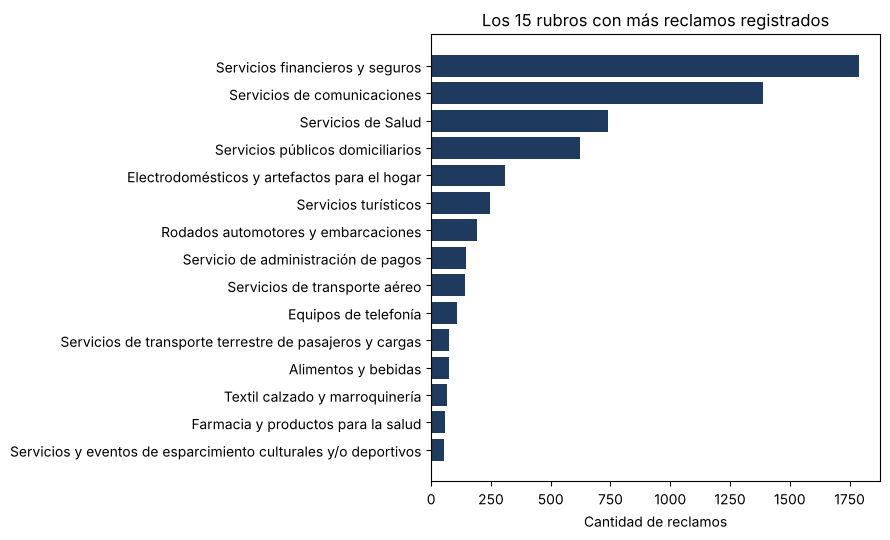

In [9]:
# Gráfico de barras horizontales de los 15 rubros más frecuentes (se invierte el orden para que el mayor quede arriba).
top = vc.head(15)[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index, top.values, color="#1F3A5F")
ax.set_xlabel("Cantidad de reclamos")
ax.set_title("Los 15 rubros con más reclamos registrados")
plt.tight_layout()
plt.savefig(FIG / "01_rubros_top15.png", dpi=150)
plt.show()

**Variable objetivo:** `rubro` (en su versión agrupada, `rubro_agrupado`, definida en la sección 6). Indica el
rubro del bien o servicio reclamado. Sus valores posibles se listan en la sección 6.

Las clases están **muy desbalanceadas**: unos pocos rubros concentran la mayoría de los reclamos y muchos
tienen muy pocos casos. Con tan pocos ejemplos, un modelo no puede aprender a reconocer esos rubros, por lo que
conviene agruparlos (sección siguiente).

## 6. Agrupación de rubros: criterio y comprobaciones

**Criterio (definido antes de entrenar):** se mantiene como clase propia todo rubro con **al menos 100
reclamos** en el dataset; los demás se agrupan en `Otros`. El umbral surge de que, con una partición
estratificada 75/25, una clase de 100 casos deja aproximadamente 75 para entrenar y 25 para evaluar. Se
compara con otros umbrales para ver qué se pierde al agrupar. El criterio usa solo la frecuencia de la
etiqueta, no las variables predictoras.

In [10]:
# Para cada umbral posible se calcula cuántas clases propias quedan, cuántos registros pasan a 'Otros'
# y qué tan chica es la clase propia más pequeña. Sirve para justificar la elección del umbral.
filas = []
for u in [30, 50, 100, 150, 200]:
    propias = int((vc >= u).sum())
    otros = int(vc[vc < u].sum())
    filas.append({
        "umbral (casos mínimos)": u,
        "clases propias": propias,
        "rubros dentro de 'Otros'": int((vc < u).sum()),
        "registros en 'Otros'": otros,
        "% en 'Otros'": round(100 * otros / len(df), 1),
        "casos de la clase propia más chica": int(vc[vc >= u].min()),
        "aprox. en prueba (25%)": int(vc[vc >= u].min() * 0.25),
    })
pd.DataFrame(filas)

,umbral (casos mínimos),clases propias,rubros dentro de 'Otros',registros en 'Otros',% en 'Otros',casos de la clase propia más chica,aprox. en prueba (25%)
0,30,20,27,258,4.0,33,8
1,50,15,32,451,7.0,54,13
2,100,10,37,775,12.0,110,27
3,150,7,40,1173,18.2,192,48
4,200,6,41,1365,21.1,245,61


In [11]:
# Se aplica el umbral elegido: se crea la columna rubro_agrupado (variable objetivo definitiva).
UMBRAL = 100
df["rubro_agrupado"] = agrupar_rubros(df["rubro"], umbral=UMBRAL)
print(df["rubro_agrupado"].value_counts().to_frame("casos").assign(porcentaje=lambda t: (100 * t["casos"] / len(df)).round(1)))

                                              casos  porcentaje
rubro_agrupado                                                 
Servicios financieros y seguros                1788        27.7
Servicios de comunicaciones                    1390        21.5
Otros                                           775        12.0
Servicios de Salud                              740        11.5
Servicios públicos domiciliarios                621         9.6
Electrodomésticos y artefactos para el hogar    308         4.8
Servicios turísticos                            245         3.8
Rodados automotores y embarcaciones             192         3.0
Servicio de administración de pagos             147         2.3
Servicios de transporte aéreo                   141         2.2
Equipos de telefonía                            110         1.7


In [12]:
# Se mira qué hay dentro de 'Otros' para saber cuánta heterogeneidad se está mezclando.
en_otros = vc[vc < UMBRAL]
print(f"'Otros' reúne {len(en_otros)} rubros y {en_otros.sum()} registros ({en_otros.sum()/len(df):.1%}).")
print("Rubros más grandes dentro de 'Otros':")
en_otros.head(10)

'Otros' reúne 37 rubros y 775 registros (12.0%).
Rubros más grandes dentro de 'Otros':


rubro
Servicios de transporte terrestre de pasajeros y cargas                    73
Alimentos y bebidas                                                        73
Textil calzado y marroquinería                                             66
Farmacia y productos para la salud                                         58
Servicios y eventos de esparcimiento culturales y/o deportivos             54
Informática                                                                46
Servicios de construcción para el hogar y comercialización de inmuebles    40
Servicios de gestoría y consultoría                                        39
Colchonerías                                                               35
Inmuebles Inmuebles por accesión                                           33
Name: count, dtype: int64

**Agrupar cambia el problema.** Con `Otros` ya no se clasifica entre todos los rubros, sino entre los 10 más
frecuentes y «cualquier otro». El umbral de 100 es una regla práctica de tamaño mínimo de muestra, **fijada antes
de entrenar** y no elegida para mejorar métricas; no proviene de una fuente oficial, y por eso se verificará con
otros umbrales.

**Qué se pierde al agrupar:** `Otros` es una clase heterogénea (reúne rubros muy distintos entre sí) y, por
lo tanto, un buen o mal resultado en esa clase no se puede interpretar como un rubro concreto. Con el
criterio elegido, los 37 rubros chicos dejan de analizarse por separado. En la etapa de modelado se comprobará la
sensibilidad del resultado a otros umbrales (50 y 200).

## 7. Partición entrenamiento / prueba

Se separa el 25 % de los datos para evaluar. La partición es **estratificada** por rubro agrupado (cada conjunto
conserva la proporción de cada clase) y usa una semilla fija. Se hace **antes** de ajustar cualquier
transformación (escalado, codificación) para que los datos de prueba no influyan en el preprocesamiento.

In [13]:
# train_test_split con stratify mantiene la proporción de cada rubro en ambos conjuntos.
tr, te = train_test_split(df, test_size=0.25, stratify=df["rubro_agrupado"], random_state=SEMILLA)
conteo = pd.DataFrame({
    "entrenamiento": tr["rubro_agrupado"].value_counts(),
    "prueba": te["rubro_agrupado"].value_counts(),
})
print("Casos por clase en entrenamiento y prueba:")
print(conteo)
print("Mínimo en entrenamiento:", conteo["entrenamiento"].min(), "| mínimo en prueba:", conteo["prueba"].min())
print()
print("Filas: entrenamiento =", len(tr), "| prueba =", len(te))
# Dato descriptivo (no es un modelo): qué proporción del conjunto de prueba es la clase más frecuente.
print("Clase más frecuente en entrenamiento:", tr["rubro_agrupado"].value_counts().idxmax())
print(f"Proporción de esa clase en el conjunto de prueba: {(te['rubro_agrupado'] == tr['rubro_agrupado'].value_counts().idxmax()).mean():.1%}")

Casos por clase en entrenamiento y prueba:
                                              entrenamiento  prueba
rubro_agrupado                                                     
Servicios financieros y seguros                        1341     447
Servicios de comunicaciones                            1042     348
Otros                                                   581     194
Servicios de Salud                                      555     185
Servicios públicos domiciliarios                        466     155
Electrodomésticos y artefactos para el hogar            231      77
Servicios turísticos                                    184      61
Rodados automotores y embarcaciones                     144      48
Servicio de administración de pagos                     110      37
Servicios de transporte aéreo                           106      35
Equipos de telefonía                                     82      28
Mínimo en entrenamiento: 82 | mínimo en prueba: 28

Filas: entrenamiento 

**Por qué aleatoria y no temporal:** el modelo no pretende predecir períodos futuros: clasifica un reclamo a partir
del perfil de la persona, sin variable temporal. Se asume que los reclamos son observaciones independientes,
supuesto que no se puede verificar (no hay identificador de persona ni de reclamo; si una misma persona figura más
de una vez, o hay filas repetidas, el resultado podría verse algo mejor de lo real). Además, los datos cubren
solo 2021-2022, y no se evalúa con períodos posteriores.

La estratificación conserva las proporciones pero no agrega ejemplos: las clases más chicas tienen pocos casos de
prueba, por lo que sus métricas serán inestables y habrá que presentarlas con esa advertencia.

La proporción de la clase más frecuente en el conjunto de prueba es el punto de referencia que habrá que
superar de forma significativa; el **modelo de referencia** (clase mayoritaria del entrenamiento, evaluada con las
mismas métricas que los demás modelos) se calculará en el notebook de modelado.

## 8. Variables sociodemográficas y territoriales

In [14]:
# Distribución de las variables que se usarán para predecir: vulnerabilidad y género.
print(df["vulnerabilidad"].value_counts().to_frame("casos").assign(porcentaje=lambda t: (100 * t["casos"] / len(df)).round(1)))
print()
print(df["genero"].value_counts().to_frame("casos"))

                     casos  porcentaje
vulnerabilidad                        
Adulto/a mayor        3410        52.8
Socio-económica       1238        19.2
Discapacidad           647        10.0
Salud                  567         8.8
NNyA                   291         4.5
Turista                151         2.3
Barrios populares       56         0.9
LGTB+                   40         0.6
Violencia de género     27         0.4
Ruralidad               13         0.2
Migrante                10         0.2
Pueblos originarios      5         0.1
Ex-combatiente           2         0.0

            casos
genero           
Femenino     3910
Masculino    2544
No Binario      3


In [15]:
# Concentración territorial: si casi todo está en pocas provincias, las demás tienen pocos casos.
prov = df["provincia_consumidor"].value_counts()
print("Provincias:", len(prov))
print(f"CABA + Buenos Aires: {(prov.get('Ciudad Autónoma de Buenos Aires', 0) + prov.get('Buenos Aires', 0)) / len(df):.1%} de los registros")
prov.head(10)

Provincias: 24
CABA + Buenos Aires: 75.6% de los registros


provincia_consumidor
Ciudad Autónoma de Buenos Aires    3496
Buenos Aires                       1386
Córdoba                             400
Santa Fe                            173
Tucumán                             144
Río Negro                           108
Chubut                               79
San Luis                             73
Neuquén                              67
San Juan                             66
Name: count, dtype: int64

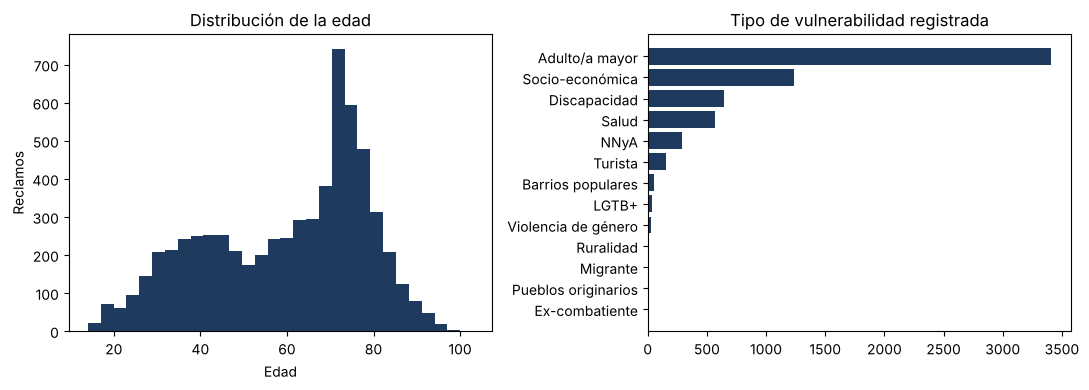

In [16]:
# Histograma de edad (forma de la distribución) y barras de vulnerabilidad (categorías dominantes).
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].hist(df["edad"], bins=30, color="#1F3A5F")
axs[0].set_title("Distribución de la edad")
axs[0].set_xlabel("Edad")
axs[0].set_ylabel("Reclamos")
v = df["vulnerabilidad"].value_counts()[::-1]
axs[1].barh(v.index, v.values, color="#1F3A5F")
axs[1].set_title("Tipo de vulnerabilidad registrada")
plt.tight_layout()
plt.savefig(FIG / "02_edad_vulnerabilidad.png", dpi=150)
plt.show()

In [17]:
# Se cruza edad con vulnerabilidad para comprobar si los datos son coherentes entre sí
# (por ejemplo, que 'NNyA' tenga menores de edad) y entender qué representa la columna edad.
print("Edad por tipo de vulnerabilidad (mínimo, mediana, máximo):")
print(df.groupby("vulnerabilidad")["edad"].agg(["count", "min", "median", "max"]).sort_values("count", ascending=False))
print()
print("Registros con edad < 18:", int((df["edad"] < 18).sum()))
print("Vulnerabilidad 'NNyA' con edad >= 18:", int(((df["vulnerabilidad"] == "NNyA") & (df["edad"] >= 18)).sum()))
print("Vulnerabilidad 'Adulto/a mayor' con edad < 60:", int(((df["vulnerabilidad"] == "Adulto/a mayor") & (df["edad"] < 60)).sum()))

Edad por tipo de vulnerabilidad (mínimo, mediana, máximo):
                     count  min  median  max
vulnerabilidad                              
Adulto/a mayor        3410   16    73.0  103
Socio-económica       1238   16    46.0   95
Discapacidad           647   15    51.0   90
Salud                  567   18    42.0   97
NNyA                   291   14    37.0   78
Turista                151   19    48.0   88
Barrios populares       56   18    46.0   94
LGTB+                   40   21    30.0   61
Violencia de género     27   17    42.0   64
Ruralidad               13   29    53.0   66
Migrante                10   35    44.0   77
Pueblos originarios      5   32    48.0   64
Ex-combatiente           2   61    68.5   76

Registros con edad < 18: 50
Vulnerabilidad 'NNyA' con edad >= 18: 252
Vulnerabilidad 'Adulto/a mayor' con edad < 60: 412


**Observación y pregunta abierta.** Muchos registros de vulnerabilidad `NNyA` tienen edad de 18 años o más, y
algunos `Adulto/a mayor` tienen menos de 60. Una **hipótesis** es que `edad` corresponda a la persona que reclama
y no a la persona afectada, pero el diccionario de la ficha no describe las columnas y no se puede confirmar; queda como pregunta para
la fuente. Mientras tanto no se corrige ni se descarta ningún registro. Además, `edad` y `vulnerabilidad` están
parcialmente relacionadas (por ejemplo, `Adulto/a mayor`), por lo que pueden ser redundantes entre sí.

## 9. Asociaciones dentro de los reclamos observados

Lo que se puede estudiar es **qué rubros aparecen con más frecuencia entre los reclamos registrados de cada
grupo**. Esto es una asociación dentro de los reclamos observados: **no** mide qué grupos están más expuestos al
problema, porque no hay información de quienes no reclamaron ni de cuántas personas de cada grupo consumen cada
servicio.

In [18]:
# Tabla cruzada con porcentajes por fila: dentro de cada tipo de vulnerabilidad, cómo se reparten los rubros.
tabla = pd.crosstab(df["vulnerabilidad"], df["rubro_agrupado"], normalize="index") * 100
orden = df["vulnerabilidad"].value_counts().index  # ordenado de más a menos casos
tabla = tabla.loc[orden].round(1)
tabla

rubro_agrupado,Electrodomésticos y artefactos para el hogar,Equipos de telefonía,Otros,Rodados automotores y embarcaciones,Servicio de administración de pagos,Servicios de Salud,Servicios de comunicaciones,Servicios de transporte aéreo,Servicios financieros y seguros,Servicios públicos domiciliarios,Servicios turísticos
vulnerabilidad,,,,,,,,,,,
Adulto/a mayor,5.6,1.7,9.4,1.9,1.8,3.7,30.9,1.7,32.3,8.3,2.8
Socio-económica,4.4,1.6,15.5,4.7,3.4,1.4,11.2,0.6,40.1,15.0,2.0
Discapacidad,5.7,2.2,17.5,7.7,2.8,13.8,19.8,1.7,17.0,10.5,1.4
Salud,0.9,0.4,5.3,0.0,1.2,80.4,3.0,1.9,2.8,3.5,0.5
NNyA,4.1,3.4,23.4,1.7,3.1,14.8,7.2,1.4,9.3,18.6,13.1
Turista,0.0,0.0,15.2,0.7,0.0,0.0,0.7,32.5,4.0,0.0,47.0
Barrios populares,7.1,3.6,14.3,5.4,3.6,1.8,17.9,0.0,32.1,14.3,0.0
LGTB+,5.0,5.0,12.5,7.5,15.0,15.0,22.5,2.5,15.0,0.0,0.0
Violencia de género,3.7,0.0,55.6,0.0,3.7,3.7,7.4,3.7,11.1,0.0,11.1


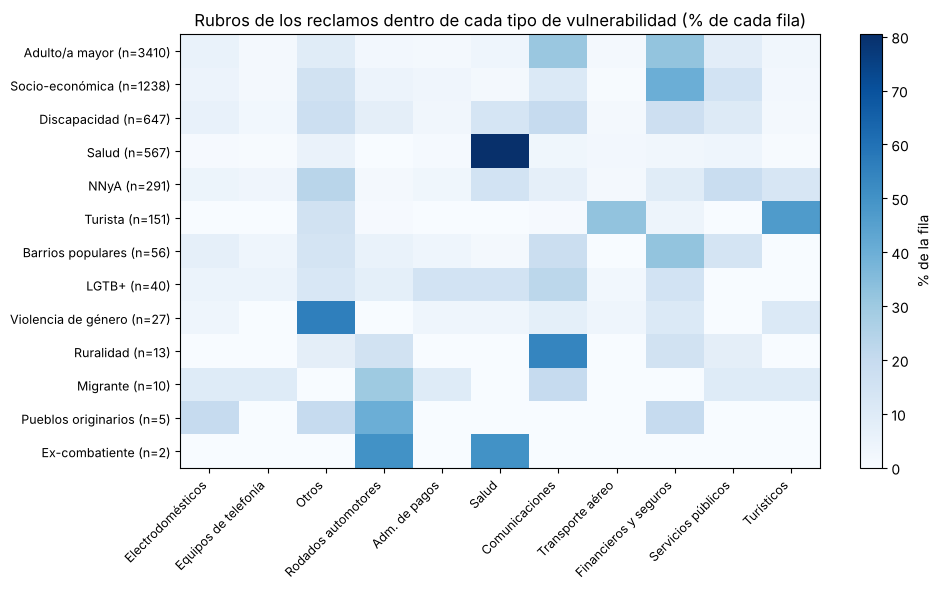

In [19]:
# Mapa de calor de la tabla anterior. Se acortan los nombres de rubros para que las etiquetas se lean bien
# y se muestra la cantidad de casos (n) de cada fila, porque las filas chicas son poco confiables.
cortos = {
    "Electrodomésticos y artefactos para el hogar": "Electrodomésticos",
    "Equipos de telefonía": "Equipos de telefonía",
    "Rodados automotores y embarcaciones": "Rodados automotores",
    "Servicio de administración de pagos": "Adm. de pagos",
    "Servicios de Salud": "Salud",
    "Servicios de comunicaciones": "Comunicaciones",
    "Servicios de transporte aéreo": "Transporte aéreo",
    "Servicios financieros y seguros": "Financieros y seguros",
    "Servicios públicos domiciliarios": "Servicios públicos",
    "Servicios turísticos": "Turísticos",
}
n_vul = df["vulnerabilidad"].value_counts()
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(tabla.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(tabla.shape[1]))
ax.set_xticklabels([cortos.get(c, c) for c in tabla.columns], rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(tabla.shape[0]))
ax.set_yticklabels([f"{v} (n={n_vul[v]})" for v in tabla.index], fontsize=9)
ax.set_title("Rubros de los reclamos dentro de cada tipo de vulnerabilidad (% de cada fila)")
fig.colorbar(im, ax=ax, label="% de la fila")
plt.tight_layout()
plt.savefig(FIG / "03_vulnerabilidad_por_rubro.png", dpi=150)
plt.show()

**Cómo leer el gráfico:** cada fila suma 100 % y muestra cómo se reparten los reclamos de ese tipo de
vulnerabilidad entre rubros. Las filas con pocos casos (por ejemplo, ex-combatientes o pueblos originarios) no son
interpretables: un solo reclamo mueve mucho el porcentaje.

**Lo que se observa (descriptivo):** entre los reclamos de `Salud` predomina el rubro Servicios de Salud (80 %);
entre los de `Turista`, los turísticos (47 %) y el transporte aéreo (32 %); entre los de `Adulto/a mayor`,
los financieros y seguros (32 %) y las comunicaciones (31 %).

**Hipótesis:** estos patrones podrían reflejar que cada tipo de vulnerabilidad se registra a
partir de la situación que originó el reclamo (por ejemplo, un problema de salud o de viaje), y no un riesgo
propio del grupo. Con estos datos no se puede confirmar: faltan datos de exposición y de cómo se asigna la
vulnerabilidad. Cualquier explicación más allá de la descripción requeriría información adicional.

In [20]:
# Intensidad de la asociación de cada variable con el rubro (V de Cramér: 0 = ninguna, 1 = total).
# Sirve para ver qué variables tienen señal y cuáles casi no aportan.
filas = []
for col in ["vulnerabilidad", "genero", "provincia_consumidor", "mes", "anio"]:
    filas.append({"variable": col, "V de Cramér con rubro_agrupado": round(cramer_v(df[col], df["rubro_agrupado"]), 3)})
pd.DataFrame(filas).sort_values("V de Cramér con rubro_agrupado", ascending=False)

,variable,V de Cramér con rubro_agrupado
0,vulnerabilidad,0.290
4,anio,0.109
2,provincia_consumidor,0.088
1,genero,0.077
3,mes,0.071


El V de Cramér mide la intensidad de la asociación entre dos variables categóricas (0 = ninguna; 1 = total).
Se interpreta solo como asociación descriptiva en estos reclamos; no es causal ni mide exposición.
`vulnerabilidad` es la variable más asociada con el rubro; las demás tienen una asociación más baja. Algunos
valores del V de Cramér pueden verse algo inflados cuando hay muchas categorías con pocos casos (por ejemplo,
provincias).

## 10. Variable temporal (`mes_anio_tratamiento`)

La fecha que trae el dataset es la de **tratamiento** del reclamo. Si el objetivo es clasificar un reclamo **al
momento de ingresarlo**, esa fecha todavía podría no estar disponible, y entonces no correspondería usarla.
No se conoce con certeza cuándo se registra (el diccionario de la ficha no lo aclara).

Período: 2021-01 a 2022-12 | 24 meses
Reclamos por mes: mínimo 105 | máximo 426


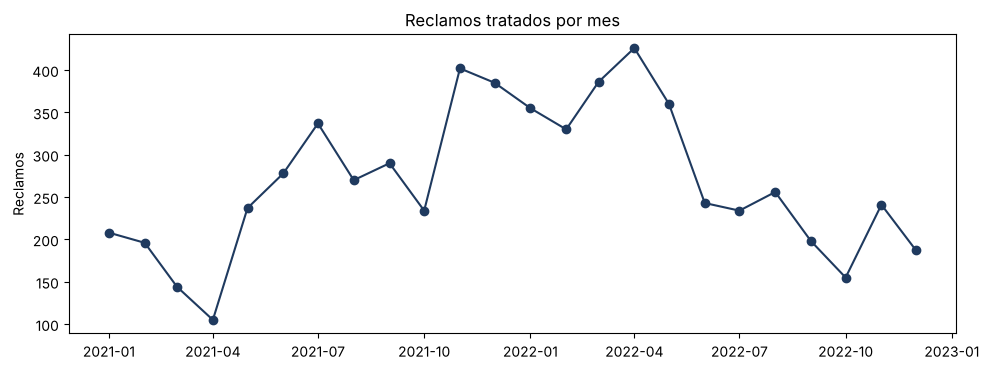

In [21]:
# Se convierte mes + año en una fecha real para poder graficar la evolución en el tiempo.
meses = {"ene": 1, "feb": 2, "mar": 3, "abr": 4, "may": 5, "jun": 6, "jul": 7, "ago": 8, "sep": 9, "oct": 10, "nov": 11, "dic": 12}
df["periodo"] = pd.to_datetime(dict(year=df["anio"], month=df["mes"].map(meses), day=1))
por_mes = df.groupby("periodo").size()  # cantidad de reclamos tratados en cada mes
print("Período:", por_mes.index.min().strftime("%Y-%m"), "a", por_mes.index.max().strftime("%Y-%m"), "|", len(por_mes), "meses")
print("Reclamos por mes: mínimo", por_mes.min(), "| máximo", por_mes.max())
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(por_mes.index, por_mes.values, marker="o", color="#1F3A5F")
ax.set_title("Reclamos tratados por mes")
ax.set_ylabel("Reclamos")
plt.tight_layout()
plt.savefig(FIG / "04_reclamos_por_mes.png", dpi=150)
plt.show()

**Decisión para el escenario principal:** no usar `mes` ni `anio`. Razones: (1) no se sabe si la fecha de
tratamiento está disponible al ingresar el reclamo; (2) su asociación con el rubro es baja (sección 9, V de
Cramér de `mes` y `anio` frente a la de `vulnerabilidad`). Es una decisión de diseño razonada con estos datos
descriptivos; si agregarlas mejora o no un modelo se comprobará en la etapa de modelado como análisis de sensibilidad,
presentado por separado. Aclaración: esa comprobación responderá a otra pregunta (usar información que quizá
no se conoce al ingreso).

## 11. El motivo del reclamo: ¿puede revelar el rubro?

El motivo se podría seleccionar a partir de un rubro ya asignado, y en ese caso revelaría indirectamente la
respuesta. Como no se sabe cómo se registra, se mide cuánto del rubro se puede deducir del motivo.

In [22]:
# Tabla motivo x rubro. La 'pureza' de un motivo es la fracción de sus reclamos que cae en su rubro más frecuente:
# 1 significa que ese motivo aparece siempre con un único rubro (lo revela por completo).
ct = pd.crosstab(df["motivo"], df["rubro"])
pureza = ct.max(axis=1) / ct.sum(axis=1)
peso = ct.sum(axis=1) / ct.values.sum()   # peso de cada motivo en el total de reclamos
print("Motivos distintos:", len(ct))
print("Pureza ponderada (fracción de reclamos cuyo rubro es el más frecuente de su motivo):", round(float((pureza * peso).sum()), 3))
exclusivos = pureza[pureza == 1].index
print("Motivos que aparecen siempre con un único rubro:", len(exclusivos), "de", len(ct), "| cubren", f"{peso[exclusivos].sum():.1%} de los reclamos")
print()
print("Ejemplos de motivos que determinan el rubro:")
print(ct.loc[exclusivos].idxmax(axis=1).head(8).to_string())

Motivos distintos: 49
Pureza ponderada (fracción de reclamos cuyo rubro es el más frecuente de su motivo): 0.495
Motivos que aparecen siempre con un único rubro: 25 de 49 | cubren 14.1% de los reclamos

Ejemplos de motivos que determinan el rubro:
motivo
Aumento de cuota no autorizado/no notificado con anticipación debida                                               Servicios de Salud
Baja de efectores y/o profesionales de la cartilla de prestaciones médicas                                         Servicios de Salud
Cancelación o supresión de vuelos                                                                       Servicios de transporte aéreo
Cumplimiento parcial o defectuoso de la prestación del servicio educativo                                      Servicios de Enseñanza
Cumplimiento parcial o defectuoso de la prestación médica o de cobertura de la medicación prescripta               Servicios de Salud
Debito de servicios no solicitados                                         

In [23]:
# Contraste: motivos genéricos que se reparten entre muchos rubros (cuántos rubros distintos tiene cada uno).
rubros_por_motivo = (ct > 0).sum(axis=1).sort_values(ascending=False)
print("Motivos que aparecen en más rubros distintos:")
print(rubros_por_motivo.head(5).to_string())

Motivos que aparecen en más rubros distintos:
motivo
Incumplimiento de Oferta Promociones y/o Bonificaciones. Art. 7 de la Ley 24.240    28
Prácticas Abusivas                                                                  26
Problemas de fraude o estafa                                                        26
Precios                                                                             22
Cumplimiento parcial o defectuoso de la prestación del servicio                     22


**Resultado:** una parte de los motivos aparece siempre con un único rubro (por ejemplo, «Cancelación o
supresión de vuelos» solo en transporte aéreo), por lo que el motivo puede revelar el rubro, y otros son genéricos
y aparecen en muchos rubros. Por eso: (a) el análisis principal **no usa** el motivo; (b) si se incorpora como
escenario complementario, se presenta aclarando esta limitación y como respuesta a una pregunta distinta
(clasificar el rubro a partir del motivo y el perfil), no como una mejora del modelo principal.

## 12. Guardado del dataset normalizado

In [24]:
# Se guarda el dataset limpio (sin tocar el original) en data/interim, con la variable objetivo agrupada.
INTERIM.parent.mkdir(parents=True, exist_ok=True)
columnas = ["rubro", "rubro_agrupado", "motivo", "vulnerabilidad", "mes_anio_tratamiento", "mes", "anio",
            "edad", "genero", "provincia_consumidor", "provincia_id"]
df[columnas].to_csv(INTERIM, index=False, encoding="utf-8")
print("Guardado en data/interim/", INTERIM.name, "-", len(df), "filas")

Guardado en data/interim/ consumidores_normalizado.csv - 6457 filas


## 13. Preprocesamiento para el modelado

**Variables predictoras del escenario principal:** `vulnerabilidad`, `genero`, `provincia_consumidor` (categóricas)
y `edad` (numérica). Se excluyen `motivo` (puede revelar el rubro), `mes`/`anio` (disponibilidad incierta),
`provincia_id` (duplica a la provincia) y `rubro` (es la variable a predecir).

**Momento de la predicción (supuesto):** el modelo se pensó para usarse **cuando se ingresa un reclamo**, con el
perfil de la persona (vulnerabilidad, edad, género, provincia) y antes de que se conozca el rubro. Se asume que
esos datos están disponibles en ese momento; el diccionario de la ficha no describe las columnas y no se pudo confirmar. Por eso no se
usan el motivo (puede revelar el rubro) ni la fecha de tratamiento (puede no existir al ingreso). Evaluar el
modelo contra la realidad requeriría comparar sus predicciones con el rubro finalmente registrado en reclamos
nuevos, algo que este dataset histórico no permite.

**Transformaciones:**
- **Codificación one-hot** de las categóricas: los modelos necesitan números. Las categorías con menos de 5
  casos en entrenamiento se agrupan en una categoría «infrecuente» para no crear columnas casi vacías.
- **Escalado (estandarización) de `edad`**: se resta la media y se divide por el desvío para llevarla a una escala
  comparable con las columnas 0/1. Se hace porque hay modelos que trabajan con distancias (como K-NN) y, sin
  escalar, la variable de mayor magnitud pesaría más. **El escalado no sirve para eliminar redundancia ni
  correlación entre variables**; solo pone las variables en una escala común.
- Las transformaciones se **ajustan solo con el conjunto de entrenamiento** y luego se aplican al de prueba, para
  que el conjunto de prueba no influya en el preprocesamiento.

In [25]:
# Listas de variables predictoras: categóricas (se codifican) y numéricas (se escalan).
CAT = ["vulnerabilidad", "genero", "provincia_consumidor"]
NUM = ["edad"]

# ColumnTransformer aplica una transformación distinta a cada grupo de columnas:
#  - OneHotEncoder: una columna 0/1 por categoría (handle_unknown evita errores si en prueba aparece
#    una categoría que no estaba en entrenamiento; min_frequency agrupa las muy raras).
#  - StandardScaler: pone la edad en media 0 y desvío 1.
preprocesador = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5, sparse_output=False), CAT),
    ("num", StandardScaler(), NUM),
])

# fit_transform en entrenamiento (aprende las categorías y la media/desvío) y transform en prueba
# (aplica lo aprendido, sin volver a ajustar): así no hay fuga de información del conjunto de prueba.
X_tr = preprocesador.fit_transform(tr[CAT + NUM])
X_te = preprocesador.transform(te[CAT + NUM])
nombres = [n.split("__", 1)[1] for n in preprocesador.get_feature_names_out()]
X_tr = pd.DataFrame(X_tr, columns=nombres, index=tr.index)
X_te = pd.DataFrame(X_te, columns=nombres, index=te.index)
y_tr = tr["rubro_agrupado"]
y_te = te["rubro_agrupado"]

print("Forma de X_entrenamiento:", X_tr.shape, "| X_prueba:", X_te.shape)
print("Columnas generadas:", len(nombres), "(", sum(c != "edad" for c in nombres), "de categorías + 1 de edad escalada )")

Forma de X_entrenamiento: (4842, 39) | X_prueba: (1615, 39)
Columnas generadas: 39 ( 38 de categorías + 1 de edad escalada )


In [26]:
# Verificación del escalado: en entrenamiento la edad escalada debe tener media ~0 y desvío ~1.
# En prueba no será exactamente 0 y 1 (se usó la media/desvío del entrenamiento), y eso es lo correcto.
print("edad escalada - entrenamiento: media =", round(X_tr["edad"].mean(), 3), "| desvío =", round(X_tr["edad"].std(ddof=0), 3))
print("edad escalada - prueba:        media =", round(X_te["edad"].mean(), 3), "| desvío =", round(X_te["edad"].std(ddof=0), 3))
print()
# Verificación de la codificación: cada fila debe tener exactamente un 1 por variable categórica (3 en total).
cols_cat = [c for c in nombres if c != "edad"]
print("Unos por fila en las columnas de categorías (esperado 3):", sorted(set(X_tr[cols_cat].sum(axis=1).astype(int))))
print("Valores faltantes en X_entrenamiento / X_prueba:", int(X_tr.isna().sum().sum()), "/", int(X_te.isna().sum().sum()))
X_tr.head(3)

edad escalada - entrenamiento: media = -0.0 | desvío = 1.0
edad escalada - prueba:        media = -0.02 | desvío = 1.011

Unos por fila en las columnas de categorías (esperado 3): [3]
Valores faltantes en X_entrenamiento / X_prueba: 0 / 0


,vulnerabilidad_Adulto/a mayor,vulnerabilidad_Barrios populares,vulnerabilidad_Discapacidad,vulnerabilidad_LGTB+,vulnerabilidad_Migrante,vulnerabilidad_NNyA,vulnerabilidad_Ruralidad,vulnerabilidad_Salud,vulnerabilidad_Socio-económica,vulnerabilidad_Turista,...,provincia_consumidor_Río Negro,provincia_consumidor_Salta,provincia_consumidor_San Juan,provincia_consumidor_San Luis,provincia_consumidor_Santa Cruz,provincia_consumidor_Santa Fe,provincia_consumidor_Santiago del Estero,provincia_consumidor_Tierra del Fuego Antártida e Islas del Atlántico Sur,provincia_consumidor_Tucumán,edad
2710,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.100781
213,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.862764
2991,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.331977


In [27]:
# Se guardan los conjuntos ya procesados en data/processed, para usarlos en el notebook de modelos.
PROCESSED.mkdir(parents=True, exist_ok=True)
X_tr.to_csv(PROCESSED / "X_train.csv", index=False)
X_te.to_csv(PROCESSED / "X_test.csv", index=False)
y_tr.to_csv(PROCESSED / "y_train.csv", index=False, header=True)
y_te.to_csv(PROCESSED / "y_test.csv", index=False, header=True)
print("Guardados en data/processed/: X_train, X_test, y_train, y_test")

Guardados en data/processed/: X_train, X_test, y_train, y_test


## 14. Resumen de decisiones para el modelado

1. **Afirmaciones:** los resultados se interpretan como asociaciones dentro de los reclamos registrados entre
   enero de 2021 y diciembre de 2022; no se habla de exposición ni de grupos «más afectados». Las explicaciones
   posibles se presentan como hipótesis.
2. **Variables del modelo principal:** vulnerabilidad, edad, género y provincia. Sin mes ni año de tratamiento
   (posible no disponibilidad al ingreso) y sin motivo (puede revelar el rubro).
3. **Rubros:** clases con al menos 100 reclamos + `Otros`; se verificó el mínimo por clase en entrenamiento y
   prueba y se hará una comprobación de sensibilidad con otros umbrales.
4. **Preprocesamiento:** partición estratificada 75/25 (semilla 42), codificación one-hot y escalado de `edad`,
   ajustados solo con el entrenamiento. Los datos quedan en `data/processed/`.
5. **Modelo de referencia (etapa de modelado):** clase mayoritaria elegida con el conjunto de entrenamiento y evaluada en
   el mismo conjunto de prueba y con las mismas métricas que los demás modelos.
6. **Desbalance:** regresión logística y árbol de decisión admiten `class_weight`; K-NN no. En K-NN,
   `weights` solo pondera el voto de los vecinos y **no** equivale a ponderar clases. Verificar la sintaxis en la
   documentación vigente de scikit-learn.
7. **Registros repetidos:** no se eliminan por falta de identificador.
